# Practical 1



✅ Write a data structure that indexes the data (a) by user and (b) by movie

✅ Plot rating distributions of data

✅ Are there power laws in the data? Is it scale-free? (Note that each user rated at least 20 movies. Truncation will skew the power law that you’d expect…)

✅ Write a data structure that indexes the data (a) by user and (b) by movie


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import csv
from itertools import islice
import random


user_to_index = {}
index_to_user = []

item_to_index = {}
index_to_item = []

data_by_user = []
data_by_item = []

data_by_user_train = []
data_by_user_test = []

data_by_item_train = []
data_by_item_test = []

cut_off = 0.2

with open('/content/drive/MyDrive/Downloads/archive/ml-32m/ratings.csv', 'r') as csvfile:
    reader = csv.reader(csvfile)

    next(reader)  #skip the header

    for row in reader:
        user_id = int(row[0])
        movie_id = int(row[1])
        rating = float(row[2])

        if user_id not in user_to_index:
            m = len(index_to_user)
            user_to_index[user_id] = m
            index_to_user.append(user_id)

            data_by_user.append([])

            data_by_user_test.append([])
            data_by_user_train.append([])

        else:
            m = user_to_index[user_id]

        if movie_id not in item_to_index:
            n = len(index_to_item)
            item_to_index[movie_id] = n
            index_to_item.append(movie_id)

            data_by_item.append([])

            data_by_item_test.append([])
            data_by_item_train.append([])

        else:
            n = item_to_index[movie_id]

        # splitting both user and item datasets
        if random.random() > cut_off:
            data_by_user_train[m].append((n, rating))
            data_by_item_train[n].append((m, rating))

        else:
            data_by_user_test[m].append((n, rating))
            data_by_item_test[n].append((m, rating))


        data_by_user[m].append((n, rating))
        data_by_item[n].append((m, rating))


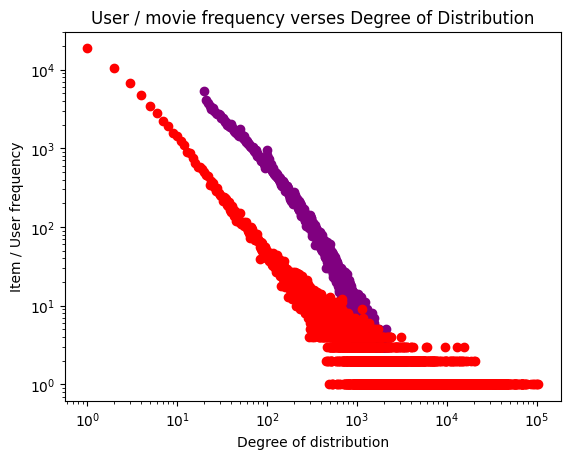

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

rating_by_user = []
rating_by_movie = []

for user in data_by_user:
    rating_by_user.append(len(user))

for movie in data_by_item:
    rating_by_movie.append(len(movie))

user_rating_count = Counter(rating_by_user)
movie_rating_count = Counter(rating_by_movie)

users_degree = np.array(list(user_rating_count.keys()))
user_frequency = np.array(list(user_rating_count.values()))

movies_degree = np.array(list(movie_rating_count.keys()))
movie_frequency = np.array(list(movie_rating_count.values()))

plt.scatter(users_degree, user_frequency, color="purple")
plt.scatter(movies_degree, movie_frequency, color="red")
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Degree of distribution')
plt.ylabel('Item / User frequency')
plt.title('User / movie frequency verses Degree of Distribution')
plt.savefig('ratings_distribution.pdf')
plt.show()

✅ Are there power laws in the data? Is it scale-free? (Note that each user rated at least 20 movies. Truncation will skew the power law that you’d expect…)


# Practical 2

✅ Build a model that finds maximum likelihood estimate for user + item biases with alternating least squares

✅ Plot the loss function (negative log likelihood) over training iterations, using data_by_user_train. It should go down monotonically!

Note that if you plotted the loss function using data_by_movie_train, the answers would be the same

✅ Plot the root mean squared error over training iterations, using data_by_user_train. What does it converge to?

✅ Plot the root mean squared error for data_by_user_test after each training iteration. What does it converge to? Does it follow the training error?

In [ ]:
import csv
from itertools import islice
import random


user_to_index = {}
index_to_user = []

item_to_index = {}
index_to_item = []

data_by_user = []
data_by_item = []

data_by_user_train = []
data_by_user_test = []

data_by_item_train = []
data_by_item_test = []

cut_off = 0.2

with open('/content/drive/MyDrive/Downloads/archive/ml-32m/ratings.csv', 'r') as csvfile:
    reader = csv.reader(csvfile)

    next(reader)  #skip the header

    for row in list(islice(reader, 100000)):
        user_id = int(row[0])
        movie_id = int(row[1])
        rating = float(row[2])

        if user_id not in user_to_index:
            m = len(index_to_user)
            user_to_index[user_id] = m
            index_to_user.append(user_id)

            data_by_user.append([])

            data_by_user_test.append([])
            data_by_user_train.append([])

        else:
            m = user_to_index[user_id]

        if movie_id not in item_to_index:
            n = len(index_to_item)
            item_to_index[movie_id] = n
            index_to_item.append(movie_id)

            data_by_item.append([])

            data_by_item_test.append([])
            data_by_item_train.append([])

        else:
            n = item_to_index[movie_id]

        # splitting both user and item datasets
        if random.random() > cut_off:
            data_by_user_train[m].append((n, rating))
            data_by_item_train[n].append((m, rating))

        else:
            data_by_user_test[m].append((n, rating))
            data_by_item_test[n].append((m, rating))


        data_by_user[m].append((n, rating))
        data_by_item[n].append((m, rating))

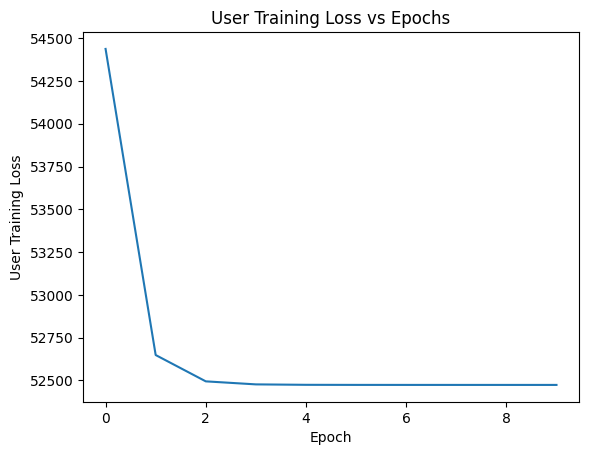

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

M = len(data_by_user)
N = len(data_by_item)

user_biases = np.zeros((M))
item_biases = np.zeros((N))

lambda_constant = 2
gamma_constant = 0.005
num_epochs = 10

user_training_loss_history = []
user_test_loss_history = []

user_train_rmse = []
user_test_rmse = []

for epoch in range(num_epochs):

    for m in range(M):
        bias = 0
        user_counter = 0

        # Updating user_biases
        for n, rating in data_by_user_train[m]:
            bias += lambda_constant * (rating - item_biases[n])
            user_counter += 1
        bias = bias / (lambda_constant * user_counter + gamma_constant)
        user_biases[m] = bias

    # Updating item_biases
    for n in range(N):
        bias = 0
        item_counter = 0
        for m, rating in data_by_item_train[n]:
            bias += lambda_constant * (rating - user_biases[m])
            item_counter += 1
        bias = bias / (lambda_constant * item_counter + gamma_constant)
        item_biases[n] = bias

    # Calculating train loss

    training_loss = 0.0
    test_loss = 0.0
    negative_log_likelihood = 0.0

    user_train_counter = 0
    train_rmse_error = 0.0

    user_test_counter = 0
    test_rmse_error = 0.0

    for m in range(M):
        for n_movie, r in data_by_user_train[m]:
            error = r - user_biases[m] - item_biases[n_movie]
            negative_log_likelihood += error ** 2
            negative_log_likelihood = (lambda_constant / 2) * negative_log_likelihood
    negative_log_likelihood += ((gamma_constant / 2) * np.sum(user_biases ** 2)) + ((gamma_constant / 2) * np.sum(item_biases ** 2))

    user_training_loss_history.append(negative_log_likelihood)

    # Calculating rmse for data by user train
    user_train_counter = 0
    for m in range(M):
        for n_movie, r in data_by_user_train[m]:
            user_train_counter += 1
            error = r - user_biases[m] - item_biases[n_movie]
            training_loss += error ** 2

    train_rmse_error = (training_loss / user_train_counter) ** 0.5

    user_train_rmse.append(train_rmse_error)



    # Caculating train loss and rmse for data by user test
    for m in range(M):
        for n_movie, r in data_by_user_test[m]:
            user_test_counter += 1
            error = r - user_biases[m] - item_biases[n_movie]
            test_loss += error ** 2

    user_test_loss_history.append(test_loss)

    test_rmse_error = (test_loss / user_test_counter) ** 0.5
    user_test_rmse.append(test_rmse_error)

# Training_loss
epochs = np.array(range(num_epochs))
user_training_loss = np.array(user_training_loss_history)
plt.xlabel('Epoch')
plt.ylabel('User Training Loss')
plt.title('User Training Loss vs Epochs')
plt.plot(epochs, user_training_loss)
plt.savefig('user_training_loss.pdf')
plt.show()



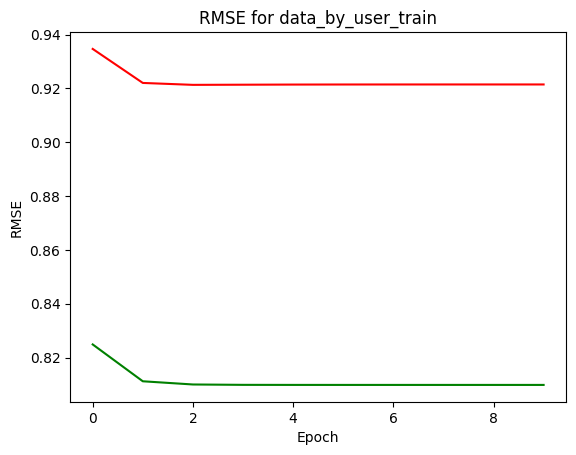

In [ ]:


epochs = np.array(range(num_epochs))
user_rmse = np.array(user_train_rmse)
test_rmse = np.array(user_test_rmse)
plt.plot(epochs, user_rmse, color='Green')
plt.plot(epochs, test_rmse, color='red')
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.title('RMSE for data_by_user_train')
plt.savefig('user_rmse.pdf')
plt.show()


# Practical 3


✅ Add user and item factors (latent trait vectors or matrices U and V)

✅ Add a sensible regularizer to your loss function

✅ Build a model that finds maximum likelihood estimate for user + item biases + latent trait vectors / factors with alternating least squares using data_by_user_train and data_by_movie_train

✅ Plot the loss function (negative log likelihood) over training iterations using data_by_user_train. It should go down monotonically!

✅ Plot the root mean squared error over training iterations using data_by_user_train and data_by_user_test . What does it converge to?

[np.float64(0.9337586028773031)]
[np.float64(0.9337586028773031), np.float64(0.9203723948555782)]
[np.float64(0.9337586028773031), np.float64(0.9203723948555782), np.float64(0.9209972175363261)]
[np.float64(0.9337586028773031), np.float64(0.9203723948555782), np.float64(0.9209972175363261), np.float64(0.9209195168944818)]
[np.float64(0.9337586028773031), np.float64(0.9203723948555782), np.float64(0.9209972175363261), np.float64(0.9209195168944818), np.float64(0.920646236432832)]
[np.float64(0.9337586028773031), np.float64(0.9203723948555782), np.float64(0.9209972175363261), np.float64(0.9209195168944818), np.float64(0.920646236432832), np.float64(0.9201982541676397)]
[np.float64(0.9337586028773031), np.float64(0.9203723948555782), np.float64(0.9209972175363261), np.float64(0.9209195168944818), np.float64(0.920646236432832), np.float64(0.9201982541676397), np.float64(0.9196779032604239)]
[np.float64(0.9337586028773031), np.float64(0.9203723948555782), np.float64(0.9209972175363261), np.

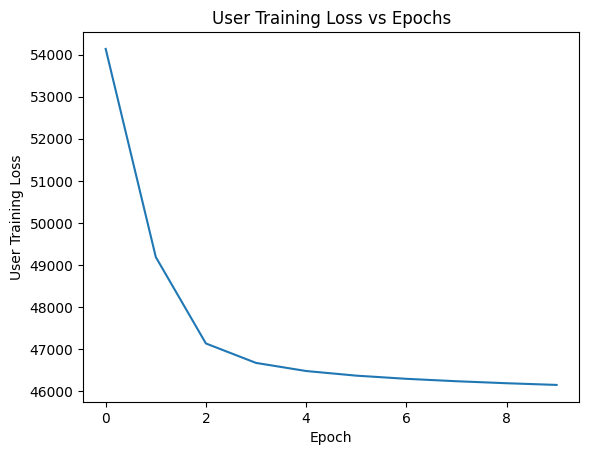

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

M = len(data_by_user)
N = len(data_by_item)

user_biases = np.zeros((M))
item_biases = np.zeros((N))

lambda_constant = 2
gamma_constant = 0.01
tau = 20
num_epochs = 10

k = 5 # no of latent traits
user_vectors = np.random.normal(0, 0.1, (M, k))
item_vectors = np.random.normal(0, 0.1, (N, k))

user_training_loss_history = []

user_train_rmse = []
user_test_rmse = []

for epoch in range(num_epochs):

    for m in range(M):
        bias = 0
        user_counter = 0

        user_bias_squares = 0

        # Updating user_biases in data by user train
        for n, rating in data_by_user_train[m]:
            user_dot_product = user_vectors[m] @ item_vectors[n]
            bias += lambda_constant * (rating - item_biases[n] - user_dot_product)
            user_counter += 1
        bias = bias / (lambda_constant * user_counter + gamma_constant)
        user_biases[m] = bias

        # Updating user_vectors
        vector_b = np.zeros(k)
        matrix_A = (tau / lambda_constant) * np.eye(k)

        for n, rating in data_by_user_train[m]:
            v = item_vectors[n]
            user_new_rating = rating - user_biases[m] - item_biases[n]
            matrix_A += np.outer(v, v)
            vector_b += v * user_new_rating
        user_vector = np.linalg.solve(matrix_A, vector_b)
        user_vectors[m] = user_vector

    for n in range(N):
        bias = 0
        item_counter = 0


        # Updating item_biases
        for m, rating in data_by_item_train[n]:
            item_dot_product = user_vectors[m] @ item_vectors[n]
            bias += lambda_constant * (rating - user_biases[m] - item_dot_product)
            item_counter += 1
        bias = bias / (lambda_constant * item_counter + gamma_constant)
        item_biases[n] = bias


        # Updating item_vectors
        matrix_B = (tau / lambda_constant) * np.eye(k)
        vector_c = np.zeros(k)

        for m, rating in data_by_item_train[n]:
            new_movie_rating = rating - user_biases[m] - item_biases[n]
            u = user_vectors[m]
            vector_c += u * new_movie_rating
            matrix_B += np.outer(u, u)
        item_vector = np.linalg.solve(matrix_B, vector_c)
        item_vectors[n] = item_vector


    # Calculating train loss for data by user train

    training_loss = 0.0
    test_loss = 0.0

    negative_log_likelihood = 0.0


    user_train_counter = 0
    user_test_counter = 0

    for m in range(M):
        for n_movie, r in data_by_user_train[m]:
            error = r - np.inner(user_vectors[m], item_vectors[n_movie]) - user_biases[m] - item_biases[n_movie]
            negative_log_likelihood += error ** 2
    negative_log_likelihood = (lambda_constant / 2) * negative_log_likelihood

    negative_log_likelihood += ((gamma_constant / 2) * np.sum(user_biases ** 2)) + ((gamma_constant / 2) * np.sum(item_biases ** 2))
    negative_log_likelihood += (tau / 2) * (np.sum(user_vectors ** 2)) + (tau / 2) * (np.sum(item_vectors ** 2))


    user_training_loss_history.append(negative_log_likelihood)


    # Calculating rmse for data by user train
    for m in range(M):
        for n_movie, r in data_by_user_train[m]:
            user_train_counter += 1
            error = r - np.inner(user_vectors[m], item_vectors[n_movie]) - user_biases[m] - item_biases[n_movie]
            training_loss += error ** 2

    train_rmse_error = (training_loss / user_train_counter) ** 0.5

    user_train_rmse.append(train_rmse_error)


    # Calculating rmse for data by user test
    for m in range(M):
        for n_movie, r in data_by_user_test[m]:
            user_test_counter += 1
            error = r - np.dot(user_vectors[m], item_vectors[n_movie]) - user_biases[m] - item_biases[n_movie]
            test_loss += error ** 2

    test_rmse_error = (test_loss / user_test_counter) ** 0.5

    user_test_rmse.append(test_rmse_error)

    print(user_test_rmse)


print(user_train_rmse)
epochs = np.array(range(num_epochs))
user_training_loss = np.array(user_training_loss_history)
plt.xlabel('Epoch')
plt.ylabel('User Training Loss')
plt.title('User Training Loss vs Epochs')

plt.plot(epochs, user_training_loss)
plt.savefig('user_training_loss_with_regularization.pdf')
plt.show()

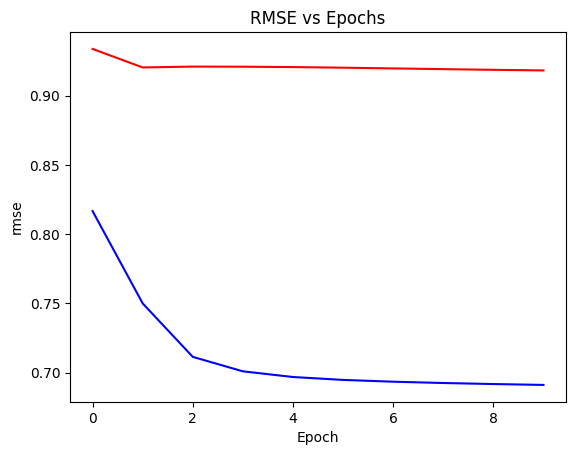

In [ ]:
rmse_user_train = np.array(user_train_rmse)
rmse_user_test = np.array(user_test_rmse)

plt.plot(epochs, rmse_user_train, color='Blue')
plt.plot(epochs, rmse_user_test, color='red')
plt.xlabel('Epoch')
plt.ylabel('rmse')
plt.title('RMSE vs Epochs')
plt.savefig('rmse_user_with_regularization.pdf')

plt.show()

# Practical 4

✅ Split the MovieLens 25M (or 32M) dataset into a training and a test set.
We won’t do cross-validation in this practical, but we will check whether we are overfitting on a test set! How will you create a sensible split?

✅ Adapt your code so that you only use the training set for optimizing parameters. Measure the RMSE on the training set and test set!
Plots the train and test RMSE on the same axis as you progress. Can you show where overfitting happens?

Is there more overfitting with K=20 latent dimensions than K=10? Or not? For which users? Is there underfitting anywhere? Do changes of λ and τ affect this?

✅ If you have settings of K, λ and τ that you like, train on the full dataset (next)


✅ Train on all 25M (or 32M) ratings. You may have to make your algorithm parallel to get this to train faster :)

✅ Show that if a user liked movie X (your choice) the recommendations Y make sense.
That is, create a “dummy user” that gave some movie like a “Lord of the Rings” five stars. Are the top recommendations other “Lord of the Rings” movies? You’ll need the 25M dataset for this to start looking really nice.

✅ Can you find and show which movies as polarizing?
Some polarizing that quickly narrows down a user’s taste once you know whether they like / dislike it. Typically movies with unusually long trait vectors v


Tricks of the trade:
Create a “dummy user” that gave some movie like a “Lord of the Rings” five stars. Are the top recommendations other “Lord of the Rings” movies? You’ll need the 25M dataset for this to start looking really nice. You used something like:
score_for_item[n] = user_trait_vector[m].inner(item_trait_vector[n]) + item_bias[n]
for all movies n. (Your recommendation score for a user is independent of the user bias, hence you didn’t add that.) This will not look nice because some “high bias” or popular movies will invariably always sit at the top. To increase the personalization component, try ranking with
score_for_item[n] = user_trait_vector[m].inner(item_trait_vector[n]) + 0.05 * item_bias[n]
where the contribution of the item bias is downplayed.

✅ Experiment! What works?


Tricks of the trade:
After ranking on:
score_for_item[n] = user_trait_vector[m].inner(item_trait_vector[n]) + 0.05 * item_bias[n]
you may still see some strange movies at the top of the list. They would be movies with, say, less than 100 ratings in your training data set. Filter them out to get cleaner results.

✅ Experiment! Does it make a difference? Let’s explore why on the next slides…


In [ ]:
import csv
from itertools import islice
import random

from numba import njit, prange, types
from numba.typed import List


user_to_index = {}
index_to_user = []

item_to_index = {}
index_to_item = []

data_by_user = []
data_by_item = []

data_by_user_train = []
data_by_user_test = []

data_by_item_train = []
data_by_item_test = []

cut_off = 0.2

with open('/content/drive/MyDrive/Downloads/archive/ml-32m/ratings.csv', 'r') as csvfile:
    reader = csv.reader(csvfile)

    next(reader)  #skip the header

    for row in reader:
        user_id = int(row[0])
        movie_id = int(row[1])
        rating = float(row[2])

        if user_id not in user_to_index:
            m = len(index_to_user)
            user_to_index[user_id] = m
            index_to_user.append(user_id)

            data_by_user.append([])

            data_by_user_test.append([])
            data_by_user_train.append([])

        else:
            m = user_to_index[user_id]

        if movie_id not in item_to_index:
            n = len(index_to_item)
            item_to_index[movie_id] = n
            index_to_item.append(movie_id)

            data_by_item.append([])

            data_by_item_test.append([])
            data_by_item_train.append([])

        else:
            n = item_to_index[movie_id]

        # splitting both user and item datasets
        if random.random() > cut_off:
            data_by_user_train[m].append((n, rating))
            data_by_item_train[n].append((m, rating))

        else:
            data_by_user_test[m].append((n, rating))
            data_by_item_test[n].append((m, rating))


        data_by_user[m].append((n, rating))
        data_by_item[n].append((m, rating))



In [ ]:
# convert user_training data for numba
rating_type = types.Tuple((types.int64, types.float64))

user_list_type = types.ListType(rating_type)
data_by_user_train_numba = List.empty_list(user_list_type)

for user_ratings in data_by_user_train:
    user_ratings_numba = List.empty_list(rating_type)

    for n, rating in user_ratings:
        user_ratings_numba.append((int(n), float(rating)))

    data_by_user_train_numba.append(user_ratings_numba)


# convert item_training data for numba
item_list_type = types.ListType(rating_type)
data_by_item_train_numba = List.empty_list(item_list_type)

for item_ratings in data_by_item_train:
    item_ratings_numba = List.empty_list(rating_type)

    for m, rating in item_ratings:
        item_ratings_numba.append((int(m), float(rating)))

    data_by_item_train_numba.append(item_ratings_numba)

# convert user_testing data for numba
rating_type = types.Tuple((types.int64, types.float64))

user_list_type = types.ListType(rating_type)
data_by_user_test_numba = List.empty_list(user_list_type)

for user_ratings in data_by_user_test:
    user_ratings_numba = List.empty_list(rating_type)

    for n, rating in user_ratings:
        user_ratings_numba.append((int(n), float(rating)))

    data_by_user_test_numba.append(user_ratings_numba)



In [ ]:
!pip install numba

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

M = len(data_by_user)
N = len(data_by_item)

user_biases = np.zeros((M))
item_biases = np.zeros((N))

lambda_constant = 1.8
gamma_constant = 0.02
tau = 0.05
num_epochs = 10

k = 10 # no of latent traits
user_vectors = np.random.normal(0, 0.1, (M, k))
item_vectors = np.random.normal(0, 0.1, (N, k))

user_training_loss_history = []
user_test_loss_history = []

user_train_rmse = []
user_test_rmse = []

In [ ]:
@njit(parallel=True)
def update_user_biases(
    data_by_user_train,
    user_biases,
    user_vectors,
    item_vectors,
    item_biases,
    lambda_constant,
    gamma_constant
):
    for m in prange(M):
        bias = 0
        user_counter = 0
        user_bias_squares = 0

        # Updating user_biases in data by user train

        for n, rating in data_by_user_train[m]:
            user_dot_product = user_vectors[m] @ item_vectors[n]
            bias += lambda_constant * (rating - item_biases[n] - user_dot_product)
            user_counter += 1
        bias = bias / (lambda_constant * user_counter + gamma_constant)
        user_biases[m] = bias
    return user_biases


In [ ]:
@njit(parallel=True)
def update_user_vectors(
    data_by_user_train,
    user_biases,
    item_biases,
    user_vectors,
    item_vectors,
    k,
    tau,
    lambda_constant
):
    for m in prange(M):
        # Updating user_vectors
        vector_b = np.zeros(k)
        matrix_A = (tau / lambda_constant) * np.eye(k)

        for n, rating in data_by_user_train[m]:
            v = item_vectors[n]
            user_new_rating = rating - user_biases[m] - item_biases[n]
            matrix_A += np.outer(v, v)
            vector_b += v * user_new_rating
        user_vector = np.linalg.solve(matrix_A, vector_b)
        user_vectors[m] = user_vector
    return user_vectors


In [ ]:
@njit(parallel=True)
def update_item_biases(
    data_by_item_train,
    user_biases,
    user_vectors,
    item_vectors,
    item_biases,
    lambda_constant,
    gamma_constant
):
    for n in prange(N):
        bias = 0
        item_counter = 0

        # Updating item_biases
        for m, rating in data_by_item_train[n]:
            item_dot_product = user_vectors[m] @ item_vectors[n]
            bias += lambda_constant * (rating - user_biases[m] - item_dot_product)
            item_counter += 1
        bias = bias / (lambda_constant * item_counter + gamma_constant)
        item_biases[n] = bias
    return item_biases

In [ ]:
@njit(parallel=True)
def update_item_vectors(
    data_by_item_train,
    user_biases,
    item_biases,
    user_vectors,
    item_vectors,
    k,
    tau,
    lambda_constant
):
    for n in prange(N):
        # Updating item_vectors
        matrix_B = (tau / lambda_constant) * np.eye(k)
        vector_c = np.zeros(k)

        for m, rating in data_by_item_train[n]:
            new_movie_rating = rating - user_biases[m] - item_biases[n]
            u = user_vectors[m]
            vector_c += u * new_movie_rating
            matrix_B += np.outer(u, u)
        item_vector = np.linalg.solve(matrix_B, vector_c)
        item_vectors[n] = item_vector
    return item_vectors


In [ ]:
@njit(parallel=True)
def update_user_test_biases(
    data_by_user_test,
    user_biases,
    user_vectors,
    item_vectors,
    item_biases,
    lambda_constant,
    gamma_constant
):
    for m in prange(M):
        bias = 0
        user_counter = 0
        user_bias_squares = 0

        # Updating user_biases in data by user test

        for n, rating in data_by_user_test[m]:
            user_dot_product = user_vectors[m] @ item_vectors[n]
            bias += lambda_constant * (rating - item_biases[n] - user_dot_product)
            user_counter += 1
        bias = bias / (lambda_constant * user_counter + gamma_constant)
        user_biases[m] = bias
    return user_biases


In [ ]:
# Calculating train loss for data by user train
test_loss = 0.0

user_test_counter = 0
test_rmse_error = 0.0


In [ ]:
@njit
def calculate_negative_log_likelihood(
    data_by_user_train,
    user_biases,
    user_vectors,
    item_vectors,
    item_biases,
    lambda_constant,
    gamma_constant,
    tau
):

    negative_log_likelihood = 0.0

    for m in prange(M):
        for n_movie, r in data_by_user_train[m]:
            error = r - np.dot(user_vectors[m], item_vectors[n_movie]) - user_biases[m] - item_biases[n_movie]
            negative_log_likelihood += error ** 2
    negative_log_likelihood = (lambda_constant / 2) * negative_log_likelihood

    negative_log_likelihood += ((gamma_constant / 2) * np.sum(user_biases ** 2)) + ((gamma_constant / 2) * np.sum(item_biases ** 2))
    negative_log_likelihood += (tau / 2) * (np.sum(user_vectors ** 2)) + (tau / 2) * (np.sum(item_vectors ** 2))

    return negative_log_likelihood

In [ ]:

# Calculating rmse for data by user train
@njit
def calculate_user_train_rmse(
    data_by_user_train,
    user_biases,
    user_vectors,
    item_vectors,
    item_biases,
    lambda_constant,
    gamma_constant,
    tau
):
    user_train_counter = 0.0
    training_loss = 0.0

    for m in prange(M):
        for n_movie, r in data_by_user_train[m]:
            user_train_counter += 1
            error = r - np.dot(user_vectors[m], item_vectors[n_movie]) - user_biases[m] - item_biases[n_movie]
            training_loss += error ** 2

    train_rmse_error = (training_loss / user_train_counter) ** 0.5

    return train_rmse_error

In [ ]:
# Calculating rmse for data by user test
@njit
def calculate_user_test_rmse(
    data_by_user_test,
    user_biases,
    user_vectors,
    item_vectors,
    item_biases,
    lambda_constant,
    gamma_constant,
    tau
):
    user_test_counter = 0.0
    test_loss = 0.0

    for m in prange(M):
        for n_movie, r in data_by_user_test[m]:
            user_test_counter += 1
            error = r - np.dot(user_vectors[m], item_vectors[n_movie]) - user_biases[m] - item_biases[n_movie]
            test_loss += error ** 2

    test_rmse_error = (test_loss / user_test_counter) ** 0.5

    return test_rmse_error

In [ ]:
for epoch in range(num_epochs):
    update_user_biases(
        data_by_user_train_numba,
        user_biases,
        user_vectors,
        item_vectors,
        item_biases,
        lambda_constant,
        gamma_constant,
    )
    print(user_biases[5])

    update_user_vectors(
        data_by_user_train_numba,
        user_biases,
        item_biases,
        user_vectors,
        item_vectors,
        k,
        tau,
        lambda_constant
    )
    print(user_vectors[5])

    update_item_biases(
        data_by_item_train_numba,
        user_biases,
        user_vectors,
        item_vectors,
        item_biases,
        lambda_constant,
        gamma_constant
    )
    print(item_biases[5])

    update_item_vectors(
        data_by_item_train_numba,
        user_biases,
        item_biases,
        user_vectors,
        item_vectors,
        k,
        tau,
        lambda_constant
    )
    print(item_vectors[5])

    loss = calculate_negative_log_likelihood(
        data_by_user_train_numba,
        user_biases,
        user_vectors,
        item_vectors,
        item_biases,
        lambda_constant,
        gamma_constant,
        tau
    )
    print(loss)

    train_rmse = calculate_user_train_rmse(
        data_by_user_train_numba,
        user_biases,
        user_vectors,
        item_vectors,
        item_biases,
        lambda_constant,
        gamma_constant,
        tau
    )

    print(train_rmse)

    test_rmse = calculate_user_test_rmse(
        data_by_user_test_numba,
        user_biases,
        user_vectors,
        item_vectors,
        item_biases,
        lambda_constant,
        gamma_constant,
        tau
    )
    print(test_rmse)


    user_training_loss_history.append(loss)
    user_train_rmse.append(train_rmse)
    user_test_rmse.append(test_rmse)

print(user_training_loss_history)
print(user_train_rmse)
print(user_test_rmse)

/tmp/ipykernel_1335/3186667598.py:18: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  for n, rating in data_by_user_train[m]:


3.9384371744522566
[ 4.04245765  4.228797   -6.08004086  0.3224995   6.9036259   3.24043294
  1.07114324  0.51119207  1.84222347  0.38218853]
-0.04717405708683005
[-0.1612603  -0.04300236  0.0353477  -0.07164953  0.05103993 -0.3389101
  0.0903047  -0.04114585  0.14047376  0.1328972 ]
15559032.37261935
0.818053393444766
0.925111099216602
4.100174810140649
[ 3.30713186  4.82884929 -6.43451325 -0.35368154  6.71503081  3.7279796
 -1.44307796 -0.31130899 -1.17033322  1.25282707]
-0.09498491053707857
[-0.18171259 -0.08883408  0.03808939 -0.05832859  0.094937   -0.38425344
  0.1647123   0.00154818  0.14594089  0.14353279]
13993906.066686131
0.775298987667939
0.8985073201109995
4.048683412802533
[ 1.71647929  3.81481591 -7.85242036 -1.06793903  1.87356001  6.16005021
 -2.50152386 -0.09714796 -1.23567182  0.3748318 ]
-0.15057800990127487
[-0.16886925 -0.13459229  0.01890718 -0.02589607  0.14009624 -0.39697063
  0.22651967  0.05627953  0.11302307  0.14096982]
13012907.647316054
0.747315995206453

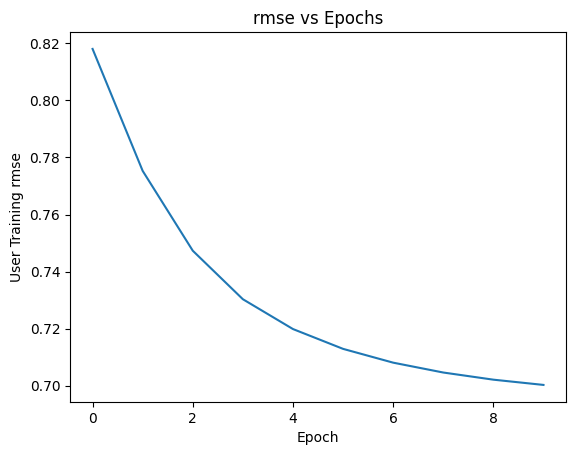

In [ ]:
epochs = np.array(range(num_epochs))
user_training_rmse = np.array(user_train_rmse)
plt.xlabel('Epoch')
plt.ylabel('User Training rmse')
plt.title('rmse vs Epochs')

plt.plot(epochs, user_training_rmse)
plt.savefig('user_training_rmse_whole_dataset.pdf')
plt.show()

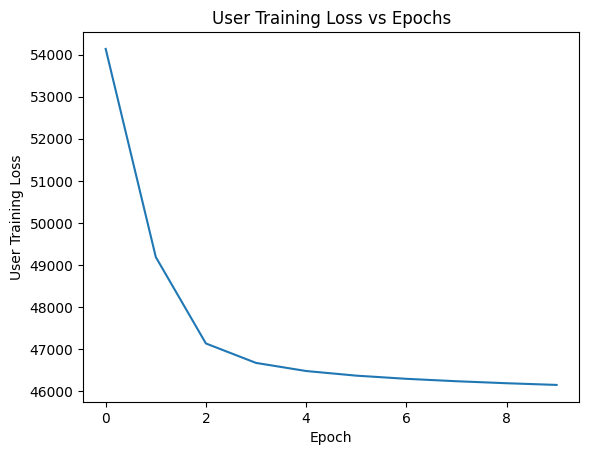

In [ ]:
epochs = np.array(range(num_epochs))
user_training_rmse = np.array(user_training_loss_history)
plt.xlabel('Epoch')
plt.ylabel('User Training Loss')
plt.title('User Training Loss vs Epochs')

plt.plot(epochs, user_training_loss)
plt.savefig('user_training_loss_whole_dataset.pdf')
plt.show()

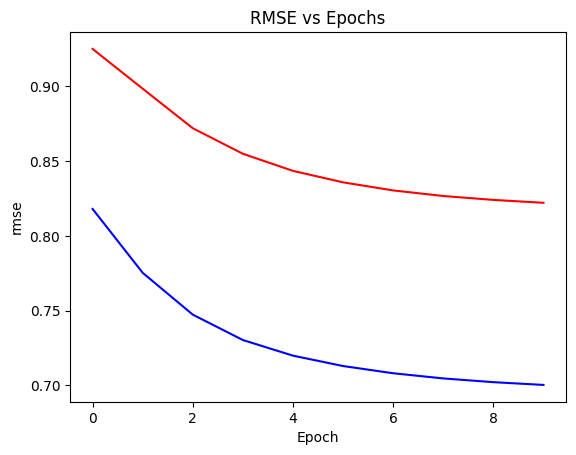

In [ ]:
rmse_user_train = np.array(user_train_rmse)
rmse_user_test = np.array(user_test_rmse)

plt.plot(epochs, rmse_user_train, color='Blue')
plt.plot(epochs, rmse_user_test, color='red')
plt.xlabel('Epoch')
plt.ylabel('rmse')
plt.title('RMSE vs Epochs')
plt.savefig('rmse_user_train_and_test_whole_dataset.pdf')
plt.show()